# Reproducing Figure 4 and two robustness checks

This notebook reproduces:
- **Figure 4**: (a) the mean adequacy-vs-land curve with and without vitamin
  B12 supplied off-farm, and (b) how much animal-product land disappears in
  each country once B12 is supplied.
- **MAR sensitivity / threshold robustness**: (1) whether "attainable on
  less land than currently cultivated" survives moving the adequacy
  threshold away from 85%, and (2) how B12's share of required land varies
  with the adequacy target.

Depends on `reproduce_figure2.ipynb`'s `country_mar_wlc` (the full-model
MAR-vs-land curves) and `df85` (currently-cultivated-vs-required) - this
notebook recomputes both from the same source data rather than importing
the other notebook, so it stays independently runnable.

For interactive exploration, see the companion dashboard:
**[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**


## 1. Setup and reference tables

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import functions as F
import functions_supply as FS
import global_var as GVARS

EXCLUDED_COUNTRIES = {"South Africa"}

df_composition = pd.read_csv("data/crop_composition_table.csv")
df_composition = df_composition.dropna(subset=["crop"]).set_index("crop")
df_composition = df_composition.fillna(0).replace(" ", 0).astype(float)
df_composition *= 10
df_composition["edible.prop"] /= 10

df_animal = pd.read_excel("data/animal_composition_table_with_carrying_capacity.xlsx", sheet_name="production ha-1")
df_animal = df_animal.set_index("animal").drop(columns=["fat"])

df_dri = pd.read_excel("data/food_comp_DRI.xlsx", sheet_name="dietary reference intake")
dri = (df_dri.drop(columns=["fat", "age group", "gender"]).iloc[0] * 365).values

df_yield = pd.read_csv("data/original/FAOSTAT_data_en_3-25-2026.csv")
df_yield = df_yield[["Item", "Year", "Area", "Value"]]
df_yield = df_yield.rename(columns={"Item": "crop", "Year": "year", "Area": "country", "Value": "yield_per_ha"})
df_yield["crop"] = df_yield["crop"].apply(lambda x: GVARS.mapping_FAO_to_RHOMIS.get(x, None))
duplicates_mapping = {
    "soya_bean": ["soya_bean", "broad_beans"], "peas": ["peas", "field_pea"],
    "millet": ["millet", "fingermillet", "pearl_millet"], "mango": ["mango", "guava"],
    "cabbage": ["cabbage", "kales"], "squash": ["squash", "pumpkin", "zucchini"],
    "sesame": ["sesame", "simsim"], "jackfruit": ["jackfruit", "passion_fruit"],
    "beans": ["beans", "haricot_bean", "green_gram"], "amaranth": ["amaranth", "teff"],
    "watermelon": ["watermelon", "melon"],
}
df_yield["crop"] = df_yield["crop"].apply(lambda x: duplicates_mapping.get(x, [x]))
df_yield = df_yield.explode("crop").reset_index(drop=True).dropna(subset=["crop"])
df_yield = df_yield.groupby(["country", "crop"]).agg({"yield_per_ha": "mean"}).reset_index()
df_yield = df_yield.rename(columns={"yield_per_ha": "mean"})
known_countries = pd.read_csv("data/processed/crop_yield_country.csv")["country"].unique()
df_yield = df_yield[df_yield["country"].isin(known_countries)]

heads = pd.read_csv("data/processed/all_heads_per_person_95percentiles.csv")
heads_long = heads.melt(id_vars="id_country", var_name="column", value_name="heads_per_person")
heads_long["animal"] = heads_long["column"].str.split("_").str[3]
heads_long = heads_long.drop(columns=["column"]).dropna(subset=["heads_per_person"])
heads_lookup = {(r.id_country, r.animal): r.heads_per_person for r in heads_long.itertuples()}

ANIMALS = list(GVARS.animal_lsu.keys())
countries_by_id = {k: v for k, v in GVARS.id_country_to_country_name.items() if v not in EXCLUDED_COUNTRIES}
animal_caps = {c: {} for c in countries_by_id.values()}
for id_country, country in countries_by_id.items():
    macro_area = GVARS.country_to_macro_area.get(country)
    lsu_per_ha = GVARS.macro_area_to_lsu_per_ha.get(macro_area)
    if not lsu_per_ha:
        continue
    for animal in ANIMALS:
        hpp = heads_lookup.get((id_country, animal), 0.0)
        animal_caps[country][animal] = hpp * GVARS.animal_lsu[animal] / lsu_per_ha
for animal in ANIMALS:
    positive = [animal_caps[c][animal] for c in animal_caps if animal_caps[c].get(animal, 0) > 0]
    floor = min(positive) if positive else None
    if floor is not None:
        for c in animal_caps:
            if animal_caps[c].get(animal, 0) <= 0:
                animal_caps[c][animal] = floor
for c in animal_caps:
    animal_caps[c]["eggs"] = animal_caps[c].get("chicken", 0.0)

countries = sorted(animal_caps.keys())
NUTRIENT_DEFAULTS = {"ca": 2500.0, "fe": 45.0, "zn": 40.0, "vit.a": 3000.0, "vit.b3": 35.0, "vit.b6": 100.0, "vit.c": 2000.0}
yearly_ul_in_mg = {k: v * 365 for k, v in NUTRIENT_DEFAULTS.items()}
land_values = np.logspace(-4, 1, 200)
print(f"{len(countries)} countries ready")

18 countries ready


## 2. Two MAR-vs-land curves per country: full model, and B12 supplied off-farm

`country_mar_wlc` is the full model (all 17 nutrients produced on-farm);
`country_mar_supply_b12` assumes vitamin B12 is supplied off-farm (its
land-linked production requirement is dropped, via `functions_supply.py`).
This is the most expensive cell here - a ~200-point land sweep per country,
solved twice.

In [2]:
country_mar_wlc = {}
country_mar_supply_b12 = {}
for country in countries:
    pc = F.creating_product_composition_table(
        country, df_yield, df_composition, df_animal,
        GVARS.country_to_macro_area, GVARS.macro_area_to_lsu_per_ha,
    )
    if pc is None:
        continue
    caps = animal_caps.get(country)
    country_mar_wlc[country] = F.compute_max_mar_fixing_caloric_intakes(
        land_values, pc, dri, min_kcal=False, yearly_ul_in_mg=yearly_ul_in_mg,
        land_ul_for_animals=caps, failure="remove_constraints",
    )
    country_mar_supply_b12[country] = FS.compute_max_mar_fixing_caloric_intakes_with_supply(
        land_values, pc, dri, min_kcal=False, yearly_ul_in_mg=yearly_ul_in_mg,
        land_ul_for_animals=caps, failure="remove_constraints",
        supplied_nutrients=["vit.b12"],
    )
print(f"solved {len(country_mar_wlc)} countries")

solved 18 countries


## 3. `df_cap`: are B12-source animals sitting at their land cap?

For each country, how much land the full-model solution spends on B12-
source animal products (those with nonzero B12 content and a positive
land cap), and whether that's at (>=98% of) the cap.

In [3]:
CAP_TOL = 0.98

rows = []
for country in countries:
    pc = F.creating_product_composition_table(
        country, df_yield, df_composition, df_animal,
        GVARS.country_to_macro_area, GVARS.macro_area_to_lsu_per_ha,
    )
    if pc is None:
        continue
    caps = animal_caps.get(country)

    full = F.max_mar_min_land_fixing_caloric_intakes(
        pc, dri, yearly_ul_in_mg=yearly_ul_in_mg, land_ul_for_animals=caps, failure="remove_constraints")
    supp = FS.max_mar_min_land_fixing_caloric_intakes_with_supply(
        pc, dri, yearly_ul_in_mg=yearly_ul_in_mg, land_ul_for_animals=caps, failure="remove_constraints",
        supplied_nutrients=["vit.b12"])
    if full[2] == -1 or supp[2] == -1:
        print(f"  (skip {country}: unsolved)")
        continue

    sol_full, sol_supp = full[1].x, supp[1].x
    idx = {p: i for i, p in enumerate(pc.index)}
    b12 = pc["vit.b12"]
    b12_animals = [a for a in caps if a in idx and float(b12.get(a, 0)) > 0 and caps[a] > 0]

    land_full_src = sum(sol_full[idx[a]] for a in b12_animals)
    land_supp_src = sum(sol_supp[idx[a]] for a in b12_animals)
    cap_total = sum(caps[a] for a in b12_animals)
    at_cap = [a for a in b12_animals if sol_full[idx[a]] >= CAP_TOL * caps[a]]

    rows.append({
        "country": country, "n_B12_animals": len(b12_animals),
        "animal_land_full": land_full_src, "animal_land_B12supplied": land_supp_src,
        "cap_total": cap_total, "cap_used_%": 100 * land_full_src / cap_total if cap_total else np.nan,
        "any_at_cap": len(at_cap) > 0, "at_cap_animals": ", ".join(at_cap) if at_cap else "-",
    })

df_cap = pd.DataFrame(rows)
pd.set_option("display.width", 190)
print(df_cap.round(3).to_string(index=False))

                         country  n_B12_animals  animal_land_full  animal_land_B12supplied  cap_total  cap_used_%  any_at_cap at_cap_animals
                    Burkina Faso              7             0.492                      0.0     13.327       3.693        True           eggs
                         Burundi              7             0.384                      0.0      1.480      25.976        True           eggs
                         Comoros              7             0.384                      0.0      1.898      20.253        True           eggs
                   Côte d'Ivoire              7             0.510                      0.0      1.361      37.443        True           eggs
Democratic Republic of the Congo              7             0.571                      0.0      1.829      31.234        True           eggs
                        Ethiopia              7             0.384                      0.0      3.819      10.064        True           eggs
             

## 4. Figure 4

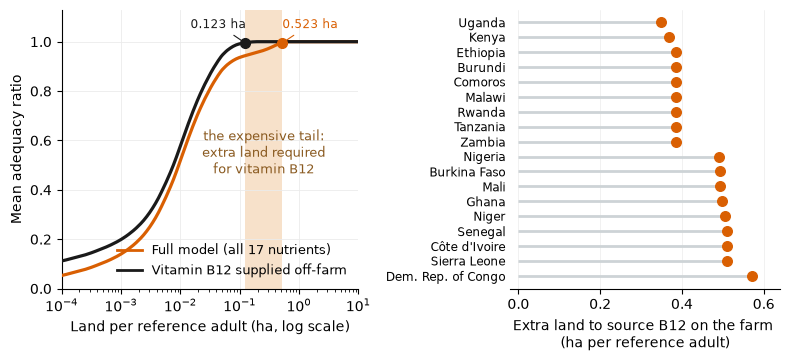

Full adequacy (0.995) reached at 0.523 ha (full model) vs 0.123 ha (B12 supplied) = 4.2x less land
Mean animal land: 0.444 ha (full) -> 0.000 ha (B12 supplied)


In [4]:
C_SUP, C_FULL, C_SHADE = "#1a1a1a", "#d95f02", "#f2c9a0"
FULL_ADQ = 0.995
analysed = [c for c in countries if c not in EXCLUDED_COUNTRIES]


def mean_curve(series_by_country, min_feasible=5):
    mat = np.full((len(land_values), len(analysed)), np.nan)
    for j, c in enumerate(analysed):
        v = np.array([m for m, res, ctrl in series_by_country[c]], dtype=float)
        v[v < 0] = np.nan
        mat[:, j] = v
    with np.errstate(invalid="ignore"):
        m = np.nanmean(mat, axis=1)
    m[np.sum(~np.isnan(mat), axis=1) < min_feasible] = np.nan
    return m


full = mean_curve(country_mar_wlc)
sup = mean_curve(country_mar_supply_b12)


def land_at(curve, target):
    ok = np.where(curve >= target)[0]
    return land_values[ok[0]] if len(ok) else np.nan


L_full, L_sup = land_at(full, FULL_ADQ), land_at(sup, FULL_ADQ)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(8, 3.5), dpi=100, gridspec_kw={"width_ratios": [1.1, 1.0]})
fig.set_facecolor("white")
for ax in (axA, axB):
    ax.set_facecolor("white")

if np.isfinite(L_full) and np.isfinite(L_sup):
    axA.axvspan(L_sup, L_full, color=C_SHADE, alpha=0.55, zorder=0, lw=0)
    axA.annotate("the expensive tail:\nextra land required\nfor vitamin B12",
                 xy=(np.sqrt(L_sup * L_full), 0.55), fontsize=9, color="#8a5a20", ha="center", va="center")

axA.plot(land_values, full, color=C_FULL, lw=2.3, zorder=3)
axA.plot(land_values, sup, color=C_SUP, lw=2.3, zorder=3)
c = 1
for L, col in ((L_full, C_FULL), (L_sup, C_SUP)):
    if np.isfinite(L):
        axA.plot([L], [FULL_ADQ], "o", color=col, ms=7, zorder=4)
        axA.annotate(f"{L:.3f} ha", xy=(L, FULL_ADQ), xytext=(L + c, 1.055), fontsize=8.5, color=col,
                     ha="center", arrowprops=dict(arrowstyle="-", color=col, lw=0.8))
    c -= 1.08
axA.set_xscale("log")
axA.set_ylim(0, 1.13)
axA.set_xlim(land_values[0], land_values[-1])
axA.set_xlabel("Land per reference adult (ha, log scale)", fontsize=10)
axA.set_ylabel("Mean adequacy ratio", fontsize=10)
axA.grid(True, color="0.92", lw=0.6)
axA.set_axisbelow(True)
for s in ("top", "right"):
    axA.spines[s].set_visible(False)
axA.legend(handles=[Line2D([], [], color=C_FULL, lw=2, label="Full model (all 17 nutrients)"),
                    Line2D([], [], color=C_SUP, lw=2, label="Vitamin B12 supplied off-farm")],
           frameon=False, fontsize=9, loc="lower right")

country_rename = {"United Republic of Tanzania": "Tanzania", "Democratic Republic of the Congo": "Dem. Rep. of Congo"}
d = df_cap.copy()
d["country"] = d["country"].map(lambda x: country_rename.get(x, x))
d = d.sort_values("animal_land_full", ascending=True)
y = np.arange(len(d))

axB.hlines(y, d["animal_land_B12supplied"], d["animal_land_full"], color="#cdd3d6", lw=2, zorder=1)
axB.scatter(d["animal_land_full"], y, s=48, color=C_FULL, zorder=3)
axB.set_yticks(y)
axB.set_yticklabels(d["country"], fontsize=8.5)
axB.invert_yaxis()
axB.set_xlim(-0.02, d["animal_land_full"].max() * 1.12)
axB.set_xlabel("Extra land to source B12 on the farm \n(ha per reference adult)", fontsize=10)
axB.grid(True, axis="x", color="0.90", lw=0.4)
axB.set_axisbelow(True)
for s in ("top", "right", "left"):
    axB.spines[s].set_visible(False)
axB.tick_params(axis="y", length=0)

fig.tight_layout()
fig.subplots_adjust(bottom=0.16)
plt.show()

print(f"Full adequacy ({FULL_ADQ}) reached at {L_full:.3f} ha (full model) vs {L_sup:.3f} ha (B12 supplied) = {L_full/L_sup:.1f}x less land")
print(f"Mean animal land: {d['animal_land_full'].mean():.3f} ha (full) -> {d['animal_land_B12supplied'].mean():.3f} ha (B12 supplied)")

## 5. `df85`: currently cultivated vs. required for adequacy

Recomputed here (same logic as `reproduce_figure2.ipynb`) since the
threshold-robustness check below needs it.

In [5]:
df_final = pd.read_csv("data/original/FINAL_results_10-12-2024.csv")
df_req = pd.read_csv("data/original/CLEAN_nut_requirements_HH_10.12.24.csv")
df_land = pd.read_csv("data/indicator_data.csv")

df_final = df_final[df_final["id_country"] != "za"].drop(columns=["fat"])
mask = ~df_final.astype(str).isin(["#NUM!"]).any(axis=1)
df_final = df_final[mask]
id_to_keep = df_final["id_unique"].values

df_req = df_req.query("id_unique in @id_to_keep").drop(columns=["fat", "Unnamed: 0"])
df_land = df_land[["id_unique", "iso_country_code", "land_cultivated_ha", "land_owned_ha", "hh_size_members"]]
df_land = df_land.query("id_unique in @id_to_keep")

df_req = pd.merge(df_req, df_land, on="id_unique", how="left")
iso_to_country = {k: v for k, v in GVARS.iso_to_country.items() if k in df_req["iso_country_code"].unique()}
country_to_iso = {v: k for k, v in iso_to_country.items()}

ref = dict(zip(df_dri.drop(columns=["fat"]).columns[2:], (df_dri.iloc[0][2:] * 365).values))
ame = df_req["kcal"] / ref["kcal"]
m = df_req[["id_unique", "iso_country_code", "land_cultivated_ha"]].copy()
m["ame"] = ame.values
agg = m.groupby("iso_country_code").agg(ame_med=("ame", "median"), land_med=("land_cultivated_ha", "median"))


def min_land_for_target(mar_series, land_values, target):
    vals = np.array(mar_series, dtype=float)
    vals[vals < 0] = np.nan
    ok = np.where(vals >= target)[0]
    return float(land_values[ok[0]]) if len(ok) else np.nan


rows = []
for country, curve in country_mar_wlc.items():
    iso = country_to_iso.get(country)
    if iso is None or iso not in agg.index:
        continue
    mar_only = [m[0] for m in curve]
    land_85_per_ame = min_land_for_target(mar_only, land_values, 0.85)
    ame_med, land_med = agg.loc[iso, "ame_med"], agg.loc[iso, "land_med"]
    rows.append({"country": country, "AME": ame_med,
                 "min_land_85_per_hh": land_85_per_ame * ame_med,
                 "current_land_per_hh": land_med,
                 "ratio": (land_85_per_ame * ame_med) / land_med if land_med else np.nan})

df85 = pd.DataFrame(rows).dropna(subset=["ratio"]).sort_values("ratio")
print(df85.round(4).to_string(index=False))

                         country    AME  min_land_85_per_hh  current_land_per_hh  ratio
                            Mali 7.9155              0.1622               7.0000 0.0232
                         Senegal 9.8482              0.1797               7.5000 0.0240
                           Niger 5.5377              0.0757               3.0000 0.0252
                          Rwanda 3.4066              0.0880               1.5000 0.0587
                          Malawi 3.0511              0.0496               0.8000 0.0620
                           Ghana 4.5688              0.1325               2.0000 0.0662
                          Zambia 3.9655              0.1368               2.0000 0.0684
     United Republic of Tanzania 4.3313              0.1494               2.0000 0.0747
                    Burkina Faso 6.5799              0.2405               3.0000 0.0802
                           Kenya 4.2143              0.0769               0.8000 0.0961
                        Ethiopia

## 6. MAR sensitivity / threshold robustness

(1) does "attainable on less land than cultivated" survive moving the 85%
adequacy threshold? (2) how does B12's share of required land vary with
the adequacy target?

Attainable on LESS land than currently cultivated:
  MAR >= 0.80:  17 of 18 countries   (median ratio 0.066, mean land 0.0297 ha/reference adult)
  MAR >= 0.85:  17 of 18 countries   (median ratio 0.088, mean land 0.0372 ha/reference adult)
  MAR >= 0.90:  17 of 18 countries   (median ratio 0.124, mean land 0.0530 ha/reference adult)
  MAR >= 0.95:  17 of 18 countries   (median ratio 0.377, mean land 0.1521 ha/reference adult)

B12 share of required land, by adequacy target:
  MAR target 0.80:  mean  19.0%  (range 15.9-29.3%, n=18)
  MAR target 0.85:  mean  23.5%  (range 15.9-37.1%, n=18)
  MAR target 0.90:  mean  32.1%  (range 25.1-40.6%, n=18)
  MAR target 0.95:  mean  69.2%  (range 50.1-88.2%, n=18)
  MAR target 1.00:  mean  82.6%  (range 62.6-90.7%, n=18)


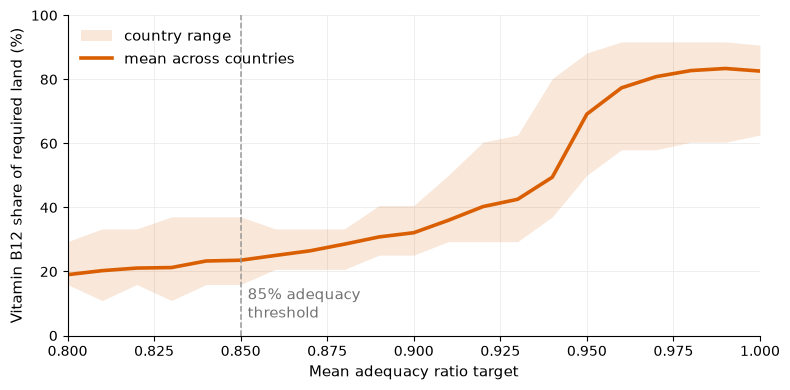

In [6]:
analysed = [c for c in countries if c not in EXCLUDED_COUNTRIES]
THRESHOLDS = [0.80, 0.85, 0.90, 0.95]


def min_land(series, target):
    v = np.array([m for m, res, ctrl in series], dtype=float)
    v[v < 0] = np.nan
    ok = np.where(v >= target)[0]
    return float(land_values[ok[0]]) if len(ok) else np.nan


cur_per_ame = dict(zip(df85["country"], df85["current_land_per_hh"] / df85["AME"]))

rows = []
for T in THRESHOLDS:
    for c in analysed:
        need = min_land(country_mar_wlc[c], T)
        cur = cur_per_ame.get(c, np.nan)
        rows.append({"target": T, "country": c, "need": need, "current": cur,
                     "ratio": need / cur if cur else np.nan,
                     "less": need < cur if np.isfinite(need * cur) else np.nan})
d1 = pd.DataFrame(rows)

print("Attainable on LESS land than currently cultivated:")
for T in THRESHOLDS:
    s = d1[d1["target"] == T]
    n_ok = int((s["less"] == True).sum())
    n = int(s["less"].notna().sum())
    print(f"  MAR >= {T:.2f}:  {n_ok} of {n} countries   (median ratio {s['ratio'].median():.3f}, mean land {s['need'].mean():.4f} ha/reference adult)")

targets = np.round(np.arange(0.80, 1.001, 0.01), 2)
rows = []
for T in targets:
    for c in analysed:
        Lf = min_land(country_mar_wlc[c], T)
        Ls = min_land(country_mar_supply_b12[c], T)
        if np.isfinite(Lf) and np.isfinite(Ls) and Lf > 0:
            rows.append({"target": T, "country": c, "share": 100 * max(Lf - Ls, 0) / Lf})
d2 = pd.DataFrame(rows)
g = d2.groupby("target")["share"]

print("\nB12 share of required land, by adequacy target:")
for T in [0.80, 0.85, 0.90, 0.95, 1.00]:
    if T in g.groups:
        s = g.get_group(T)
        print(f"  MAR target {T:.2f}:  mean {s.mean():5.1f}%  (range {s.min():.1f}-{s.max():.1f}%, n={len(s)})")

ts = sorted(d2["target"].unique())
mean = [g.get_group(t).mean() for t in ts]
lo = [g.get_group(t).min() for t in ts]
hi = [g.get_group(t).max() for t in ts]

fig, ax = plt.subplots(figsize=(8, 4))
fig.set_facecolor("white")
ax.set_facecolor("white")
ax.fill_between(ts, lo, hi, color="#d95f02", alpha=0.15, lw=0, label="country range")
ax.plot(ts, mean, "-", color="#d95f02", lw=2.6, label="mean across countries")
ax.axvline(0.85, color="0.6", ls="--", lw=1.1)
ax.text(0.852, 4, "85% adequacy\nthreshold", fontsize=11, color="0.45", va="bottom")
ax.set_xlim(0.80, 1.0)
ax.set_ylim(0, 100)
ax.set_xlabel("Mean adequacy ratio target", fontsize=11)
ax.set_ylabel("Vitamin B12 share of required land (%)", fontsize=11)
ax.grid(True, color="0.92", lw=0.6)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=11, loc="upper left")
fig.tight_layout()
plt.show()

## Notes

For interactive exploration - including a per-country drill-down into
which specific products drive the B12 land cost - see the companion
dashboard: **[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**
